
European Call Option Price = 32.5409


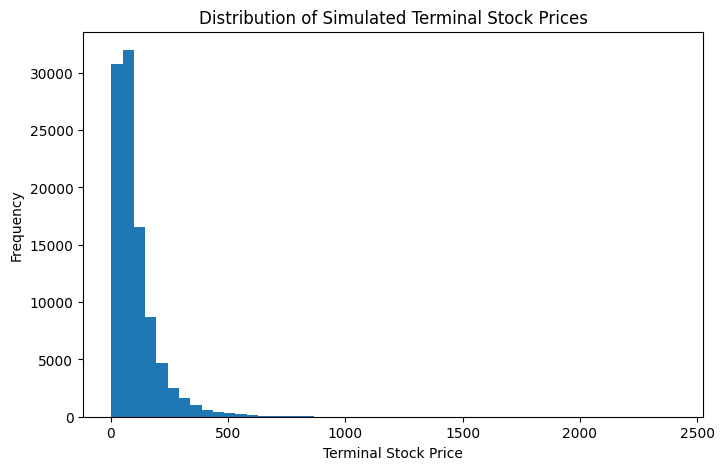

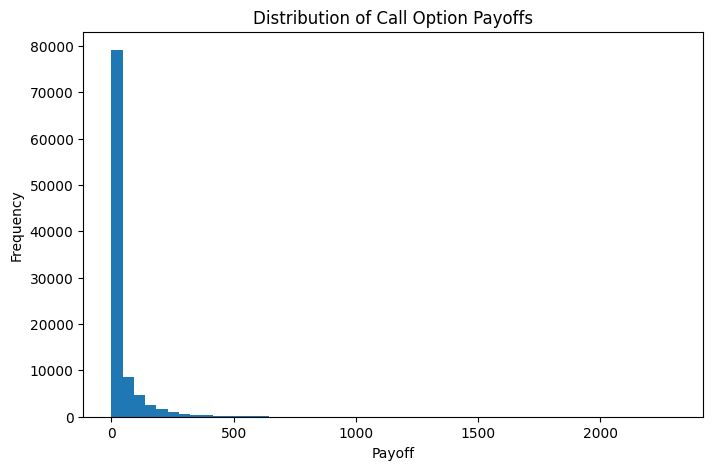

In [ ]:
# Monte Carlo Option Pricing Model (European call option)

import numpy as np
import matplotlib.pyplot as plt


# Input Parameters
def get_parameters():
    S0 = float(input("Current stock price (S0): "))
    K = float(input("Strike price (K): "))
    r = float(input("Risk-free rate (e.g. 0.05): "))
    sigma = float(input("Volatility (e.g. 0.2): "))
    T = float(input("Time to maturity (years): "))
    N = int(input("Number of simulations: "))

    return S0, K, r, sigma, T, N


# Simulate Terminal Stock Prices
def simulate_terminal_prices(S0, r, sigma, T, N):

    Z = np.random.normal(0, 1, N)

    ST = S0 * np.exp((r - 0.5 * sigma**2) * T +
                     sigma * np.sqrt(T) * Z)

    return ST


# Calculate Call Option Payoff
def calculate_call_payoff(ST, K):

    payoff = np.maximum(ST - K, 0)

    return payoff


# Monte Carlo Price
def montecarlo_price(payoff, r, T):

    avg = np.mean(payoff)

    price = np.exp(-r * T) * avg

    return price


# Main Program
def main():

    S0, K, r, sigma, T, N = get_parameters()

    ST = simulate_terminal_prices(S0, r, sigma, T, N)

    payoff = calculate_call_payoff(ST, K)

    price = montecarlo_price(payoff, r, T)

    print("\nEuropean Call Option Price =", round(price, 4))

    # Plot terminal stock prices
    plt.figure(figsize=(8, 5))
    plt.hist(ST, bins=50)
    plt.title("Distribution of Simulated Terminal Stock Prices")
    plt.xlabel("Terminal Stock Price")
    plt.ylabel("Frequency")
    plt.show()

    # Plot option payoffs
    plt.figure(figsize=(8, 5))
    plt.hist(payoff, bins=50)
    plt.title("Distribution of Call Option Payoffs")
    plt.xlabel("Payoff")
    plt.ylabel("Frequency")
    plt.show()


if __name__ == "__main__":
    main()


Monte Carlo Price = 10.0486
Black-Scholes Price = 10.0201
Absolute Error = 0.0285


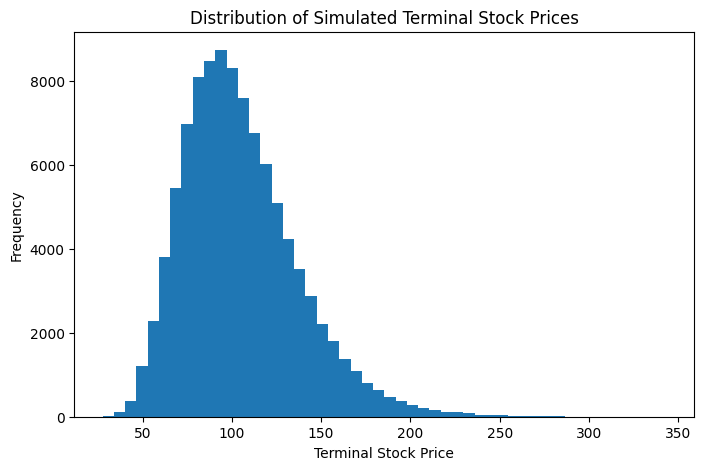

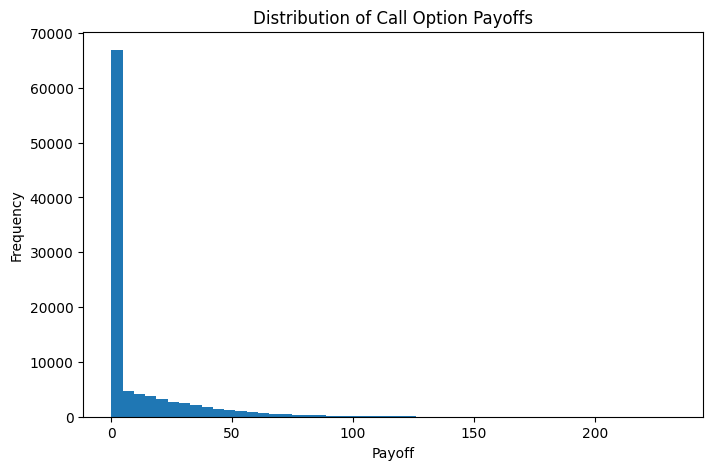

In [8]:
# Monte Carlo Option Pricing Model

import numpy as np
import matplotlib.pyplot as plt

# Input Parameters
def get_parameters():
    S0 = float(input("Current stock price (S0): "))
    K = float(input("Strike price (K): "))
    r = float(input("Risk-free rate (e.g. 0.05): "))
    sigma = float(input("Volatility (e.g. 0.2): "))
    T = float(input("Time to maturity (years): "))
    N = int(input("Number of simulations: "))

    return S0, K, r, sigma, T, N


# Simulate Terminal Stock Prices
def simulate_terminal_prices(S0, r, sigma, T, N):

    Z = np.random.normal(0, 1, N)

    ST = S0 * np.exp((r - 0.5 * sigma**2) * T +
                     sigma * np.sqrt(T) * Z)

    return ST


# Calculate Call Option Payoff
def calculate_call_payoff(ST, K):

    payoff = np.maximum(ST - K, 0)

    return payoff


# Monte Carlo Price
def montecarlo_price(payoff, r, T):

    avg = np.mean(payoff)

    price = np.exp(-r * T) * avg

    return price


import math

def black_scholes_call(S0, K, r, sigma, T):

    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    N = lambda x: 0.5 * (1 + math.erf(x / np.sqrt(2)))

    call_price = S0 * N(d1) - K * np.exp(-r * T) * N(d2)

    return call_price


# Main Program
def main():

    S0, K, r, sigma, T, N = get_parameters()

    ST = simulate_terminal_prices(S0, r, sigma, T, N)

    payoff = calculate_call_payoff(ST, K)

    price = montecarlo_price(payoff, r, T)

    bs_price = black_scholes_call(S0, K, r, sigma, T)

    print("\nMonte Carlo Price =", round(price, 4))
    print("Black-Scholes Price =", round(bs_price, 4))
    print("Absolute Error =", round(abs(price - bs_price), 4))

    # Plot terminal stock prices
    plt.figure(figsize=(8, 5))
    plt.hist(ST, bins=50)
    plt.title("Distribution of Simulated Terminal Stock Prices")
    plt.xlabel("Terminal Stock Price")
    plt.ylabel("Frequency")
    plt.show()

    # Plot option payoffs
    plt.figure(figsize=(8, 5))
    plt.hist(payoff, bins=50)
    plt.title("Distribution of Call Option Payoffs")
    plt.xlabel("Payoff")
    plt.ylabel("Frequency")
    plt.show()


if __name__ == "__main__":
    main()



European Call Option Price = 10.2063

Asian Call Option Price = 4.0821
European Std Dev (Standard): 20.635870630575695
Asian Std Dev (Standard): 9.460630564944521


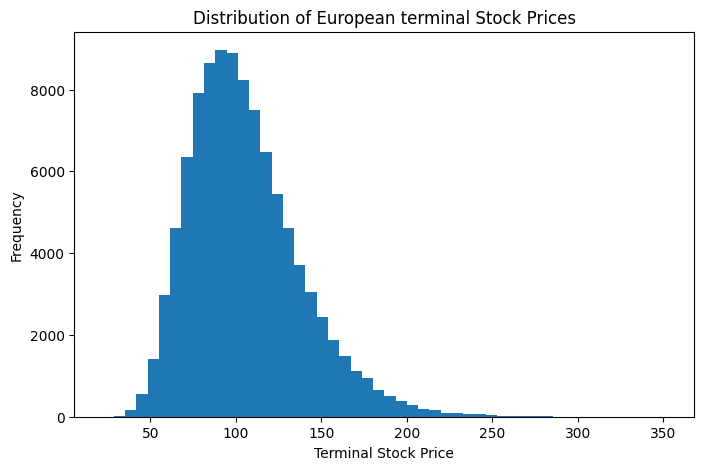

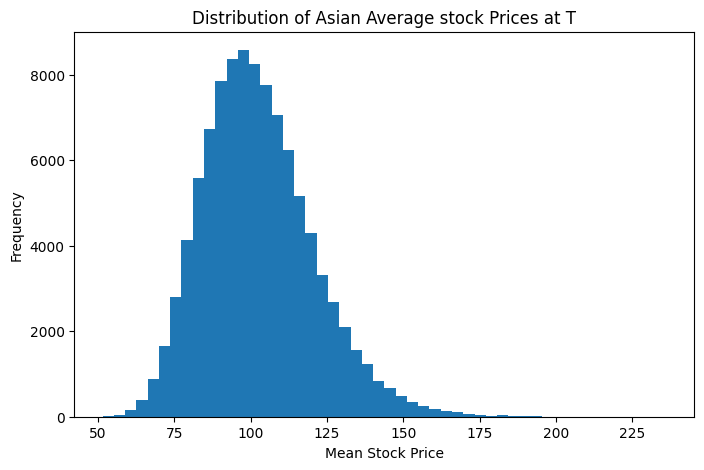

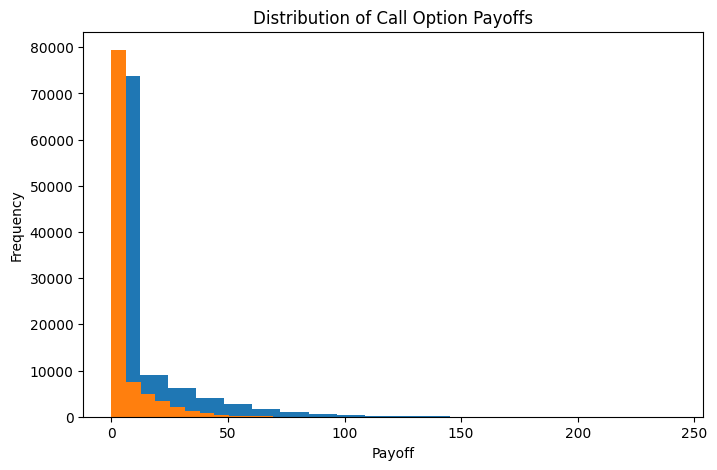

In [14]:
#montecarlo option pricing (Asian options)

import numpy as np
import matplotlib.pyplot as plt


# Input Parameters
def get_parameters():
    S0 = float(input("Current stock price (S0): "))
    K = float(input("Strike price (K): "))
    r = float(input("Risk-free rate (e.g. 0.05): "))
    sigma = float(input("Volatility (e.g. 0.2): "))
    T = float(input("Time to maturity (years): "))
    N = int(input("Number of simulations: "))

    return S0, K, r, sigma, T, N


# Simulate Terminal Stock Prices
def simulate_terminal_prices(S0, r, sigma, T, N):

    Z = np.random.normal(0, 1, N)

    ST = S0 * np.exp((r - 0.5 * sigma**2) * T +
                     sigma * np.sqrt(T) * Z)

    return ST

#simulate Savg & asian option price
def average_terminal_price(S0, r, sigma,T,N):
    Savg= []
    steps= 252
    dt=T/steps
    for i in range(N):
        S=S0
        path=[S0]
        for j in range(steps):
        
            Z = np.random.normal(0, 1)

            S = S * np.exp((r - 0.5 * sigma**2) * dt +
                            sigma * np.sqrt(dt) * Z)
            path.append(S)
        average_price= np.mean(path)
        Savg.append(average_price)

    return np.array(Savg)

def asian_option_payoff(Savg,K):
    Asianpayoff= np.maximum(Savg-K,0)
    return Asianpayoff

def asian_optionprice(Asianpayoff, r,T):
    avgpayoff= np.mean(Asianpayoff)
    asianprice= np.exp(-r*T)*avgpayoff
    return asianprice
        

# Calculate Call Option Payoff
def calculate_call_payoff(ST, K):

    payoff = np.maximum(ST - K, 0)

    return payoff


# Monte Carlo Price
def montecarlo_price(payoff, r, T):

    avg = np.mean(payoff)

    price = np.exp(-r * T) * avg

    return price


# Main Program
def main():

    S0, K, r, sigma, T, N = get_parameters()

    ST = simulate_terminal_prices(S0, r, sigma, T, N)
     
    Savg = average_terminal_price(S0, r, sigma,T,N)

    Asianpayoff= asian_option_payoff(Savg,K)

    asianprice= asian_optionprice(Asianpayoff, r,T)

    payoff = calculate_call_payoff(ST, K)

    price = montecarlo_price(payoff, r, T)

    print("\nEuropean Call Option Price =", round(price, 4))
    print("\nAsian Call Option Price =", round(asianprice, 4))
    print("European Std Dev (Standard):", np.std(payoff))
    print("Asian Std Dev (Standard):", np.std(Asianpayoff))

    # Plot terminal stock prices
    plt.figure(figsize=(8, 5))
    plt.hist(ST, bins=50)
    plt.title("Distribution of European terminal Stock Prices")
    plt.xlabel("Terminal Stock Price")
    plt.ylabel("Frequency")
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.hist(Savg, bins=50)
    plt.title("Distribution of Asian Average stock Prices at T")
    plt.xlabel("Mean Stock Price")
    plt.ylabel("Frequency")
    plt.show()

    # Plot option payoffs
    plt.figure(figsize=(8, 5))
    plt.hist(payoff, bins=20)
    plt.hist(Asianpayoff, bins=20)
    plt.title("Distribution of Call Option Payoffs")
    plt.xlabel("Payoff")
    plt.ylabel("Frequency")
    plt.show()

if __name__ == "__main__":
    main()

Black-Scholes Price = 10.0201


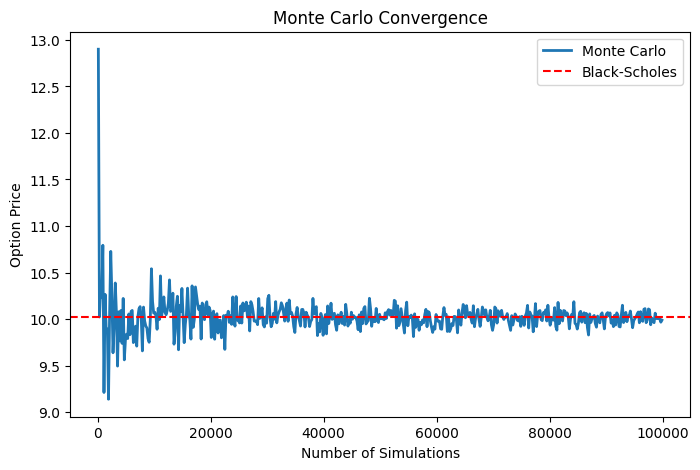

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N_list = range(100, 100001, 200)
# Input Parameters
def get_parameters():
    S0 = float(input("Current stock price (S0): "))
    K = float(input("Strike price (K): "))
    r = float(input("Risk-free rate (e.g. 0.05): "))
    sigma = float(input("Volatility (e.g. 0.2): "))
    T = float(input("Time to maturity (years): "))
    
    return S0, K, r, sigma, T


# Simulate Terminal Stock Prices
def simulate_terminal_prices(S0, r, sigma, T, N):

        Z = np.random.normal(0, 1, N)

        ST = S0 * np.exp((r - 0.5 * sigma**2) * T +
                        sigma * np.sqrt(T) * Z)

        return ST

# Calculate Call Option Payoff
def calculate_call_payoff(ST, K):

        payoff = np.maximum(ST - K, 0)

        return payoff

# Monte Carlo Price
def montecarlo_price(payoff, r, T):

        avg = np.mean(payoff)

        price = np.exp(-r * T) * avg

        return price


import math

def black_scholes_call(S0, K, r, sigma, T):

        d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

        d2 = d1 - sigma * np.sqrt(T)

        N = lambda x: 0.5 * (1 + math.erf(x / np.sqrt(2)))

        call_price = S0 * N(d1) - K * np.exp(-r * T) * N(d2)

        return call_price

# Main Program
def main():

    S0, K, r, sigma, T = get_parameters()

    pricesplot = []

    bs_price = black_scholes_call(S0, K, r, sigma, T)

    for N in N_list:

        ST = simulate_terminal_prices(S0, r, sigma, T, N)

        payoff = calculate_call_payoff(ST, K)

        price = montecarlo_price(payoff, r, T)

        pricesplot.append(price)

    print("Black-Scholes Price =", round(bs_price,4))

    plt.figure(figsize=(8,5))

    plt.plot(N_list, pricesplot,
             linewidth=2,
             label="Monte Carlo")

    plt.axhline(bs_price,
                color='red',
                linestyle='--',
                label="Black-Scholes")

    

    plt.xlabel("Number of Simulations")
    plt.ylabel("Option Price")
    plt.title("Monte Carlo Convergence")
    
    plt.legend()
    plt.show()

if __name__ == "__main__":
       main()

    





European Call Option Price = 10.0631

Asian Call Option Price = 4.0621
European Std Dev (Antithetic): 12.536986804826208
Asian Std Dev (Antithetic): 5.899908002196518


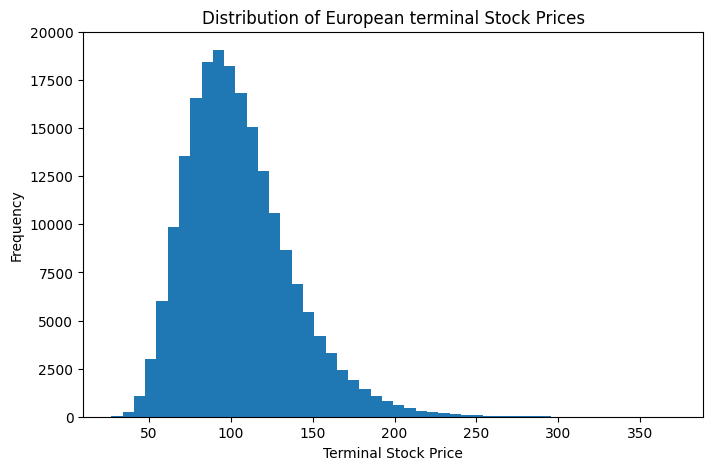

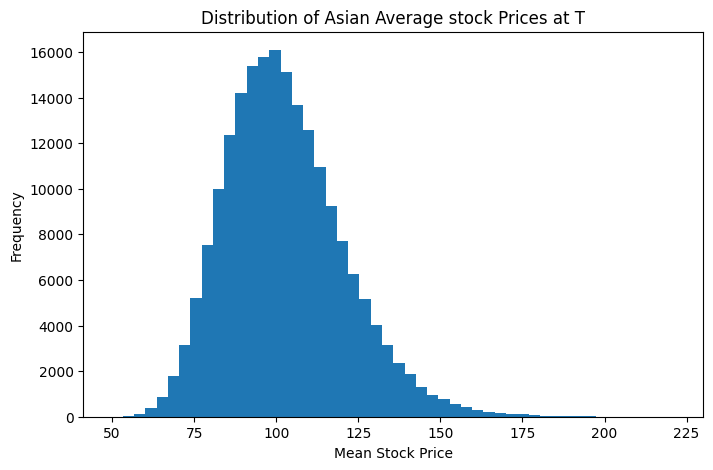

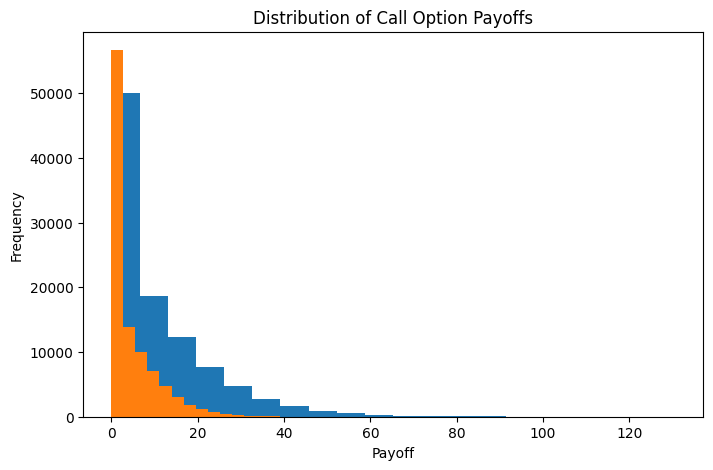

In [13]:
import numpy as np
import matplotlib.pyplot as plt


# Input Parameters
def get_parameters():
    S0 = float(input("Current stock price (S0): "))
    K = float(input("Strike price (K): "))
    r = float(input("Risk-free rate (e.g. 0.05): "))
    sigma = float(input("Volatility (e.g. 0.2): "))
    T = float(input("Time to maturity (years): "))
    N = int(input("Number of simulations: "))

    return S0, K, r, sigma, T, N


# Simulate Terminal Stock Prices
def simulate_terminal_prices(S0, r, sigma, T, N):

    Z = np.random.normal(0, 1, N)

    ST1 = S0 * np.exp((r - 0.5 * sigma**2) * T +
                     sigma * np.sqrt(T) * Z)
    ST2= S0 * np.exp((r - 0.5 * sigma**2) * T +
                            sigma * np.sqrt(T) * (-Z))
    
    return ST1,ST2

#simulate Savg & asian option price
def average_terminal_price(S0, r, sigma,T,N):
    Savg= []
    avg1=[]
    avg2=[]
    steps= 252
    dt=T/steps
    for i in range(N):
        S1 = S0
        S2 = S0

        path1 = [S0]
        path2 = [S0]

        for j in range(steps):

            Z = np.random.normal()

            S1 *= np.exp((r - 0.5*sigma**2)*dt +
                        sigma*np.sqrt(dt)*Z)

            S2 *= np.exp((r - 0.5*sigma**2)*dt +
                        sigma*np.sqrt(dt)*(-Z))

            path1.append(S1)
            path2.append(S2)

        avg1.append(np.mean(path1))
        avg2.append(np.mean(path2))
    return np.array(avg1),np.array(avg2)

def asian_option_payoff(avg1,avg2,K):
    payoff1 = np.maximum(avg1 - K, 0)
    payoff2 = np.maximum(avg2 - K, 0)

    Asianpayoff = 0.5*(payoff1 + payoff2)
    return Asianpayoff

def asian_optionprice(Asianpayoff, r,T):
    avgpayoff= np.mean(Asianpayoff)
    asianprice= np.exp(-r*T)*avgpayoff
    return asianprice
        

# Calculate Call Option Payoff
def calculate_call_payoff(ST1,ST2, K):

    payoff1 = np.maximum(ST1-K,0)
    payoff2 = np.maximum(ST2-K,0)

    payoff = 0.5*(payoff1 + payoff2)

    return payoff


# Monte Carlo Price
def montecarlo_price(payoff, r, T):

    avg = np.mean(payoff)

    price = np.exp(-r * T) * avg

    return price


# Main Program
def main():

    S0, K, r, sigma, T, N = get_parameters()

    ST1,ST2 = simulate_terminal_prices(S0, r, sigma, T, N)
     
    avg1,avg2 = average_terminal_price(S0, r, sigma,T,N)

    Asianpayoff= asian_option_payoff(avg1,avg2,K)
    asianprice= asian_optionprice(Asianpayoff, r,T)

    payoff = calculate_call_payoff(ST1,ST2, K)

    price = montecarlo_price(payoff, r, T)

    print("\nEuropean Call Option Price =", round(price, 4))
    print("\nAsian Call Option Price =", round(asianprice, 4))
    print("European Std Dev (Antithetic):", np.std(payoff))
    print("Asian Std Dev (Antithetic):", np.std(Asianpayoff))

    ST= np.concatenate((ST1,ST2))
    # Plot terminal stock prices
    plt.figure(figsize=(8, 5))
    plt.hist(ST, bins=50)
    plt.title("Distribution of European terminal Stock Prices")
    plt.xlabel("Terminal Stock Price")
    plt.ylabel("Frequency")
    plt.show()
    Saverage= np.concatenate((avg1,avg2))
    plt.figure(figsize=(8, 5))
    plt.hist(Saverage, bins=50)
    plt.title("Distribution of Asian Average stock Prices at T")
    plt.xlabel("Mean Stock Price")
    plt.ylabel("Frequency")
    plt.show()
    
    # Plot option payoffs
    plt.figure(figsize=(8, 5))
    plt.hist(payoff, bins=20)
    plt.hist(Asianpayoff, bins=20)
    plt.title("Distribution of Call Option Payoffs")
    plt.xlabel("Payoff")
    plt.ylabel("Frequency")
    plt.show()

if __name__ == "__main__":
    main()